# Member 2 — Classification Track, Part B (Adult / Census Income)

**Review 2 scope (Member 2):** two Part-B algorithms — **Bagging** (Decision Tree base estimator) and the **MLP
Classifier** (neural network).

- Section 1 walks through the full Adult preprocessing step by step. It is the **same** pipeline as Review 1 Part A
  (implemented once in `adult_prep.py`), so these models are scored on the same 9,035 test rows as every other
  classifier and can go in the consolidated 10-algorithm table.
- Metrics (all mandatory): accuracy, weighted precision / recall / F1, confusion matrix, ROC-AUC; plus macro F1 and
  balanced accuracy because the target is imbalanced.
- Each model: baseline -> `GridSearchCV` (stratified 5-fold, weighted F1) -> improvement documented -> 5-fold CV.

In [ ]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path
from IPython.display import display

from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay, classification_report)

import adult_prep
from adult_prep import RANDOM_STATE, NUM_COLS

np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid', palette='colorblind')
# joblib workers emit a harmless config-propagation warning on every parallel fit
warnings.filterwarnings('ignore', category=UserWarning)
os.environ['PYTHONWARNINGS'] = 'ignore::UserWarning'

DATA_DIR = Path('../data/raw/adult')
RESULTS_DIR = Path('../results/classification')
MODELS_DIR = Path('../models/classification')
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)
PALETTE = {'<=50K': '#0072B2', '>50K': '#D55E00'}

def save_fig(name):
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / name, dpi=150, bbox_inches='tight')

## 1. Adult dataset preprocessing

### 1.1 Load and audit

UCI ships Adult as a fixed train/test pair (32,561 + 16,281 rows). Both files are loaded and **pooled** so the project
can make its own stratified 80:20 split (guideline 7.2). The audit reports shape, dtypes, missing values (this
dataset writes missing as `?`), duplicates and the class distribution.

In [ ]:
raw_train = pd.read_csv(DATA_DIR / 'adult_train.csv')
raw_test = pd.read_csv(DATA_DIR / 'adult_test.csv')
raw = pd.concat([raw_train, raw_test], ignore_index=True)
print('train file:', raw_train.shape, '| test file:', raw_test.shape, '| pooled:', raw.shape)

audit = pd.DataFrame({
    'dtype': raw.dtypes.astype(str),
    'n_unique': raw.nunique(),
    "'?' count": [(raw[c].astype(str).str.strip() == '?').sum() for c in raw.columns],
    'NaN count': raw.isna().sum(),
})
display(audit)
print('duplicate rows (raw):', raw.duplicated().sum())
print('label spellings before cleaning:', sorted(raw['income'].astype(str).str.strip().unique()))

train file: (32561, 15) | test file: (16281, 15) | pooled: (48842, 15)


,dtype,n_unique,'?' count,NaN count
age,int64,74,0,0
workclass,object,9,2799,0
fnlwgt,int64,28523,0,0
education,object,16,0,0
education-num,int64,16,0,0
marital-status,object,7,0,0
occupation,object,15,2809,0
relationship,object,6,0,0
race,object,5,0,0
sex,object,2,0,0


duplicate rows (raw): 52
label spellings before cleaning: ['<=50K', '>50K']


**Audit findings.**
- Missing values appear only as `?` and only in three **categorical** columns: `workclass`, `occupation`,
  `native-country`. No numeric column has missing values.
- The original UCI test file writes its labels with a trailing dot (`>50K.`). The converted CSVs in this repo already
  show only two spellings, but the cleaning step still strips a trailing dot so the pipeline is safe on the raw files.
- 52 fully duplicated rows exist in the pooled data.

### 1.2 Cleaning

| Step | Choice | Why |
|---|---|---|
| Whitespace | strip every text column | `' Private'` and `'Private'` must be one category |
| Label | remove a trailing `.` | the UCI test file spells labels `>50K.`; guarantees exactly 2 classes |
| `?` values | convert to missing, **drop the row** | categorical columns: a mean/median is meaningless, a "?" category is noise; only ~7% of rows are affected |
| Duplicates | drop | identical rows add no information and can sit in both train and test |

Imputing with the most frequent value (e.g. `Private`, `Prof-specialty`) was rejected: it would invent ~2,000
occupations and bias the most common category.

In [ ]:
clean = adult_prep.load_clean(DATA_DIR)

n_pooled = len(raw)
n_missing_rows = int((raw.astype(str).apply(lambda s: s.str.strip()) == '?').any(axis=1).sum())
print(f'pooled rows: {n_pooled:,}')
print(f'rows with at least one "?": {n_missing_rows:,} ({n_missing_rows / n_pooled:.1%})')
print(f'rows after dropping "?" and duplicates: {len(clean):,} '
      f'({n_pooled - n_missing_rows - len(clean)} duplicates removed)')
print('remaining missing values:', int(clean.isna().sum().sum()))
print('label values after cleaning:', sorted(clean['income'].unique()))

pooled rows: 48,842
rows with at least one "?": 3,620 (7.4%)
rows after dropping "?" and duplicates: 45,175 (47 duplicates removed)
remaining missing values: 0
label values after cleaning: ['<=50K', '>50K']


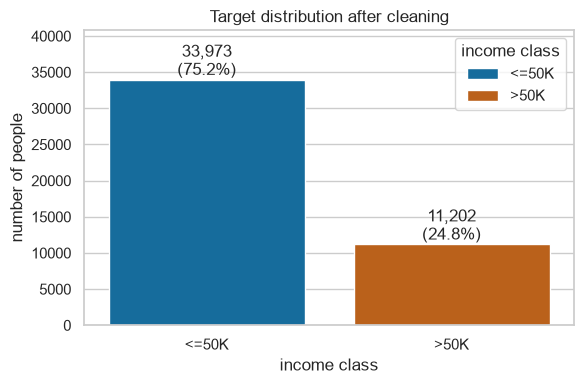

In [ ]:
counts = clean['income'].value_counts()
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=counts.index, y=counts.values, hue=counts.index, palette=PALETTE, legend=True, ax=ax)
for i, v in enumerate(counts.values):
    ax.text(i, v, f'{v:,}\n({v / counts.sum():.1%})', ha='center', va='bottom')
ax.set_title('Target distribution after cleaning')
ax.set_xlabel('income class')
ax.set_ylabel('number of people')
ax.set_ylim(0, counts.max() * 1.2)
ax.legend(title='income class')
save_fig('m2_target_distribution.png')
plt.show()

**Observation.** About 75% of people earn `<=50K`. Always predicting `<=50K` would already score ~75% accuracy, so
weighted / macro F1, balanced accuracy and ROC-AUC are reported too, and the minority class is up-weighted in training.

### 1.3 Skew treatment and feature engineering

- **`log1p` on `capital-gain` and `capital-loss`.** Both are zero for >90% of people with a very long tail
  (`capital-gain` is top-coded at 99,999). `log1p` compresses the tail and keeps zero at zero. It is applied row by
  row, so no statistic is learned from the data and nothing can leak from the test set.
- **`net_capital`** = signed `log1p(gain - loss)`: one signed number for net investment income.
- **`overtime`** = 1 if `hours-per-week` > 40: the "beyond a full-time week" effect.
- **Dropped:** `fnlwgt` (census sampling weight, unrelated to a person's income) and `education` (the text form of
  `education-num` — the same information twice).

In [ ]:
model_df = adult_prep.engineer(clean)

skew_view = pd.DataFrame({
    'skew before': clean[['capital-gain', 'capital-loss']].skew(),
    'skew after log1p': model_df[['capital-gain', 'capital-loss']].skew(),
}).round(2)
display(skew_view)

y_hi = clean['income'] == '>50K'
print('share >50K with a capital gain: %.3f | overall: %.3f' % (y_hi[clean['capital-gain'] > 0].mean(), y_hi.mean()))
print('share >50K overtime vs not: %.3f vs %.3f' % (y_hi[model_df['overtime'] == 1].mean(), y_hi[model_df['overtime'] == 0].mean()))
print('correlation of fnlwgt with the target: %.3f' % np.corrcoef(clean['fnlwgt'], y_hi)[0, 1])
print('columns kept:', model_df.columns.tolist())

,skew before,skew after log1p
capital-gain,11.78,3.08
capital-loss,4.51,4.27


share >50K with a capital gain: 0.627 | overall: 0.248
share >50K overtime vs not: 0.404 vs 0.179
correlation of fnlwgt with the target: -0.007
columns kept: ['age', 'workclass', 'education-num', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income', 'net_capital', 'overtime']


### 1.4 Stratified split, encoding and scaling (fitted on the training set only)

1. **Split first.** Stratified 80:20 split with `random_state=42` — both sets keep the same 75/25 class ratio.
2. **One-hot encoding** of the 7 nominal columns. Label encoding would invent an order between categories.
   `handle_unknown='ignore'` keeps a category never seen in training from crashing the test transform.
3. **`StandardScaler`** on the 6 numeric columns. The binary `overtime` and one-hot columns stay 0/1.
4. Encoder and scaler are **fitted on the training rows only** and then applied to both sets. Fitting on all rows
   would leak test statistics into training.

In [ ]:
data = adult_prep.split_encode_scale(model_df)
X_train, X_test = data['X_train'], data['X_test']
y_train, y_test = data['y_train'], data['y_test']
class_names = list(data['target_le'].classes_)

print('train:', X_train.shape, '| test:', X_test.shape)
print('share >50K  train: %.4f | test: %.4f' % (y_train.mean(), y_test.mean()))
print('target encoding:', dict(zip(class_names, data['target_le'].transform(class_names))))

leak_check = pd.DataFrame({'train mean': X_train[NUM_COLS].mean(), 'train std': X_train[NUM_COLS].std(),
                           'test mean': X_test[NUM_COLS].mean(), 'test std': X_test[NUM_COLS].std()}).round(3)
display(leak_check)

train: (36140, 89) | test: (9035, 89)
share >50K  train: 0.2480 | test: 0.2479
target encoding: {'<=50K': np.int64(0), '>50K': np.int64(1)}


,train mean,train std,test mean,test std
age,0.0,1.0,-0.000,1.003
education-num,-0.0,1.0,0.002,0.995
capital-gain,0.0,1.0,0.003,1.004
capital-loss,-0.0,1.0,-0.005,0.990
hours-per-week,0.0,1.0,-0.006,0.984
net_capital,-0.0,1.0,0.005,1.000


**Check.** The scaler was fitted on the training rows, so the training columns have mean 0 and std 1 exactly, while
the test columns are only close to 0 / 1 — the signature of a leakage-free scaler. The split (36,140 / 9,035 rows,
89 features) is identical to Review 1 Part A.

In [ ]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def score(model, X, y_true):
    """All required metrics for one fitted model on one data set."""
    pred = model.predict(X)
    proba = model.predict_proba(X)[:, 1]
    return {
        'accuracy': accuracy_score(y_true, pred),
        'precision_weighted': precision_score(y_true, pred, average='weighted', zero_division=0),
        'recall_weighted': recall_score(y_true, pred, average='weighted'),
        'f1_weighted': f1_score(y_true, pred, average='weighted'),
        'f1_macro': f1_score(y_true, pred, average='macro'),
        'balanced_accuracy': balanced_accuracy_score(y_true, pred),
        'roc_auc': roc_auc_score(y_true, proba),
    }

def cv_table(search, params):
    """Grid-search results as a sorted table."""
    cols = [f'param_{p}' for p in params] + ['mean_train_score', 'mean_test_score', 'std_test_score']
    return pd.DataFrame(search.cv_results_)[cols].sort_values('mean_test_score', ascending=False).reset_index(drop=True)

# balanced sample weights: each >50K row counts ~3x, countering the 75/25 imbalance
from sklearn.utils.class_weight import compute_sample_weight
sw_train = compute_sample_weight('balanced', y_train)

results, models, searches = {}, {}, {}

## 2. Bagging (Decision Tree base estimator)

Bagging = **b**ootstrap **agg**regat**ing**: train many copies of the same model, each on a bootstrap sample of the
rows (drawn with replacement), and average their predicted probabilities. A deep decision tree has **high
variance** (small data changes give a very different tree); averaging many of them cancels much of that variance.

Difference from Random Forest: Bagging gives every tree **all features** at every split; Random Forest also samples
features per split, which decorrelates the trees further.

The base estimator is a `DecisionTreeClassifier(class_weight='balanced')`, as the guideline requires.

In [ ]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

single_tree = DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE).fit(X_train, y_train)
results['Single unpruned tree (reference)'] = score(single_tree, X_test, y_test)

bag_base = BaggingClassifier(estimator=DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE),
                             n_estimators=50, oob_score=True, n_jobs=-1, random_state=RANDOM_STATE)
bag_base.fit(X_train, y_train)
results['Bagging (base)'] = score(bag_base, X_test, y_test)
print('out-of-bag accuracy of the base bagging model: %.4f' % bag_base.oob_score_)
display(pd.DataFrame({k: results[k] for k in ['Single unpruned tree (reference)', 'Bagging (base)']}).T.round(4))

out-of-bag accuracy of the base bagging model: 0.8376


,accuracy,precision_weighted,recall_weighted,f1_weighted,f1_macro,balanced_accuracy,roc_auc
Single unpruned tree (reference),0.8092,0.8154,0.8092,0.8118,0.7514,0.7591,0.7732
Bagging (base),0.8411,0.8370,0.8411,0.8386,0.7804,0.7724,0.8916


**Observation.** This is bagging's whole point in numbers. A single fully grown tree scores weighted F1 0.812 and
ROC-AUC 0.773 (its probabilities are almost all 0 or 1). Averaging 50 such trees trained on bootstrap samples lifts
weighted F1 to 0.839 and ROC-AUC to 0.892 — same model type, much lower variance.

The **out-of-bag accuracy** (0.838) is computed on the ~37% of rows each tree did not see in its bootstrap sample.
It is close to the test accuracy (0.841), so OOB gives a free validation estimate without touching the test set.

### 2.1 Tuning `n_estimators`, `max_samples` and the base tree depth

- `n_estimators`: number of bagged trees.
- `max_samples`: share of the training rows in each bootstrap sample (smaller = more diverse trees).
- `estimator__max_depth`: depth of each base tree (`None` = fully grown, maximum variance for bagging to remove).

In [ ]:
bag_grid = {
    'n_estimators': [50, 150],
    'max_samples': [0.5, 1.0],
    'estimator__max_depth': [None, 20],
}
searches['Bagging'] = GridSearchCV(
    BaggingClassifier(estimator=DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE),
                      random_state=RANDOM_STATE),
    bag_grid, scoring='f1_weighted', cv=CV, n_jobs=-1, return_train_score=True)
searches['Bagging'].fit(X_train, y_train)
print('best params:', searches['Bagging'].best_params_)
print('best CV weighted F1: %.4f' % searches['Bagging'].best_score_)
bag_cv = cv_table(searches['Bagging'], bag_grid)
display(bag_cv.round(4))

best params: {'estimator__max_depth': 20, 'max_samples': 0.5, 'n_estimators': 150}
best CV weighted F1: 0.8495


,param_n_estimators,param_max_samples,param_estimator__max_depth,mean_train_score,mean_test_score,std_test_score
0,150,0.5,20,0.9003,0.8495,0.0039
1,50,0.5,20,0.8999,0.8493,0.0029
2,150,0.5,None,0.9480,0.8488,0.0040
3,50,0.5,None,0.9451,0.8465,0.0042
4,150,1.0,20,0.9174,0.8428,0.0034
5,50,1.0,20,0.9164,0.8420,0.0038
6,150,1.0,None,0.9733,0.8402,0.0032
7,50,1.0,None,0.9726,0.8395,0.0026


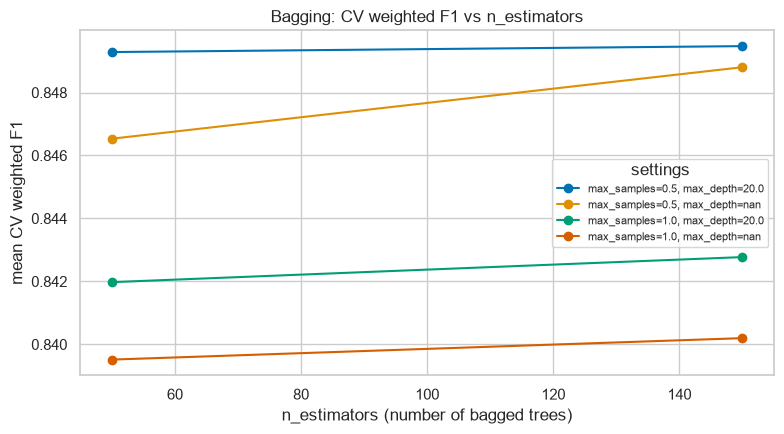

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for (ms, depth), grp in bag_cv.groupby(['param_max_samples', 'param_estimator__max_depth'], dropna=False):
    grp = grp.sort_values('param_n_estimators')
    ax.plot(grp['param_n_estimators'], grp['mean_test_score'], marker='o', label=f'max_samples={ms}, max_depth={depth}')
ax.set_title('Bagging: CV weighted F1 vs n_estimators')
ax.set_xlabel('n_estimators (number of bagged trees)')
ax.set_ylabel('mean CV weighted F1')
ax.legend(title='settings', fontsize=8)
save_fig('m2_bagging_tuning_curve.png')
plt.show()

**Observation.**
- **`max_samples=0.5` wins in every pairing** (about +0.007 CV F1): trees trained on half the rows differ more from
  each other, so averaging removes more variance. It is the smallest value in the grid, so a smaller value (e.g. 0.3)
  could be worth trying.
- **Depth-20 trees edge out fully grown ones** and have a smaller train/CV gap (0.900 vs 0.849, compared with
  0.948 vs 0.849): a little pruning per tree helps.
- **`n_estimators` barely matters** (50 vs 150 trees differ by at most 0.002). Best: `max_samples=0.5,
  estimator__max_depth=20, n_estimators=150`, CV weighted F1 0.8495.

In [ ]:
bag = searches['Bagging'].best_estimator_
models['Bagging'] = bag
results['Bagging (tuned)'] = score(bag, X_test, y_test)
display(pd.DataFrame({k: v for k, v in results.items() if k.startswith('Bagging')}).T.round(4))

,accuracy,precision_weighted,recall_weighted,f1_weighted,f1_macro,balanced_accuracy,roc_auc
Bagging (base),0.8411,0.837,0.8411,0.8386,0.7804,0.7724,0.8916
Bagging (tuned),0.8459,0.855,0.8459,0.8493,0.8027,0.8178,0.9135


**Observation.** Tuned Bagging reaches accuracy 0.846, weighted F1 **0.849** and ROC-AUC 0.914 — the highest
accuracy and weighted F1 of all classifiers so far.

## 3. MLP Classifier (neural network)

A multi-layer perceptron passes the 89 inputs through one or more **hidden layers** of neurons. Each neuron computes a
weighted sum of its inputs and applies a non-linear **activation** (`relu`: max(0, z); `tanh`: squashes to -1...1).
The output neuron gives P(`>50K`). Weights are learned with the **Adam** optimiser by back-propagating the log-loss.

- Inputs must be on a similar scale, or large features dominate the gradients — the `StandardScaler` from section 1
  handles this (tree models did not need it, the MLP does).
- `early_stopping=True` holds out 10% of the training rows and stops when their score stops improving, which limits
  overfitting. `alpha` is the L2 penalty on the weights.
- Balanced **sample weights** are passed to `fit` to counter the 75/25 imbalance, like the other models.

In [ ]:
from sklearn.neural_network import MLPClassifier

mlp_base = MLPClassifier(early_stopping=True, max_iter=300, random_state=RANDOM_STATE)   # default: one layer of 100, relu
mlp_base.fit(X_train, y_train, sample_weight=sw_train)
results['MLP (base)'] = score(mlp_base, X_test, y_test)
print('epochs until early stopping:', mlp_base.n_iter_)
pd.Series(results['MLP (base)']).round(4)

epochs until early stopping: 55


accuracy              0.8104
precision_weighted    0.8489
recall_weighted       0.8104
f1_weighted           0.8200
f1_macro              0.7752
balanced_accuracy     0.8190
roc_auc               0.9025
dtype: float64

### 3.1 Tuning `hidden_layer_sizes` and `activation`

The guideline asks for `hidden_layer_sizes` and `activation`; the L2 penalty `alpha` is tuned with them because a
bigger network needs more regularisation. Stratified 5-fold `GridSearchCV`, weighted F1, sample weights routed
through `fit`.

In [ ]:
mlp_grid = {
    'hidden_layer_sizes': [(32,), (64,), (100,), (64, 32)],     # (100,) = the base model's architecture
    'activation': ['relu', 'tanh'],
    'alpha': [1e-4, 1e-2],
}
searches['MLP'] = GridSearchCV(
    MLPClassifier(early_stopping=True, max_iter=300, random_state=RANDOM_STATE), mlp_grid,
    scoring='f1_weighted', cv=CV, n_jobs=-1, return_train_score=True)
searches['MLP'].fit(X_train, y_train, sample_weight=sw_train)
print('best params:', searches['MLP'].best_params_)
print('best CV weighted F1: %.4f' % searches['MLP'].best_score_)
mlp_cv = cv_table(searches['MLP'], mlp_grid)
mlp_cv['param_hidden_layer_sizes'] = mlp_cv['param_hidden_layer_sizes'].astype(str)
display(mlp_cv.round(4))

best params: {'activation': 'tanh', 'alpha': 0.01, 'hidden_layer_sizes': (64, 32)}
best CV weighted F1: 0.8260


,param_hidden_layer_sizes,param_activation,param_alpha,mean_train_score,mean_test_score,std_test_score
0,"(64, 32)",tanh,0.0100,0.8339,0.8260,0.0033
1,"(100,)",relu,0.0100,0.8391,0.8253,0.0028
2,"(100,)",tanh,0.0100,0.8327,0.8251,0.0024
3,"(64, 32)",relu,0.0100,0.8382,0.8251,0.0054
4,"(100,)",tanh,0.0001,0.8322,0.8250,0.0042
5,"(64, 32)",relu,0.0001,0.8441,0.8247,0.0012
6,"(32,)",tanh,0.0100,0.8295,0.8246,0.0034
7,"(64, 32)",tanh,0.0001,0.8371,0.8242,0.0024
8,"(64,)",relu,0.0001,0.8386,0.8242,0.0025
9,"(100,)",relu,0.0001,0.8383,0.8232,0.0034


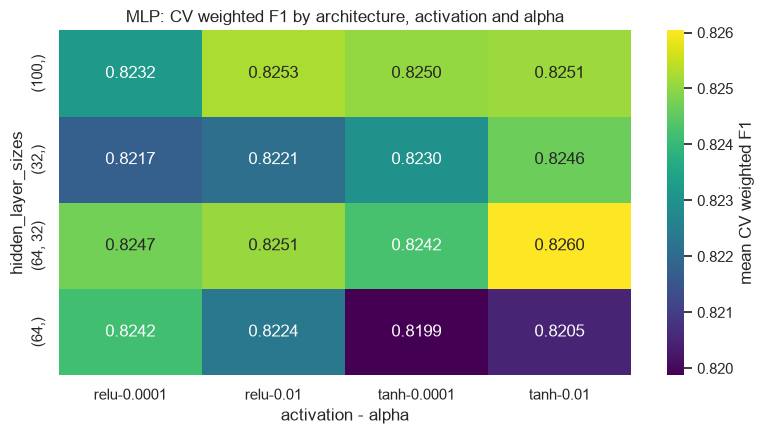

In [ ]:
heat = mlp_cv.pivot_table(index='param_hidden_layer_sizes', columns=['param_activation', 'param_alpha'],
                          values='mean_test_score')
plt.figure(figsize=(8, 4.5))
sns.heatmap(heat, annot=True, fmt='.4f', cmap='viridis', cbar_kws={'label': 'mean CV weighted F1'})
plt.title('MLP: CV weighted F1 by architecture, activation and alpha')
plt.xlabel('activation - alpha')
plt.ylabel('hidden_layer_sizes')
save_fig('m2_mlp_grid_heatmap.png')
plt.show()

**Observation.**
- All 16 settings score between 0.820 and 0.826 CV weighted F1, a spread close to the fold-to-fold noise
  (std 0.001-0.007). On this tabular data the architecture matters far less than it does for trees' depth.
- **More regularisation helps:** `alpha=0.01` is in 4 of the top 5 settings; the larger penalty keeps the weights small
  and reduces overfitting.
- The **two-layer (64, 32)** network with `tanh` is best (0.826). The base architecture `(100,)`, `relu`,
  `alpha=0.0001` was inside the grid and scored 0.823, so tuning found a better setting on CV.

In [ ]:
mlp = searches['MLP'].best_estimator_
models['MLP'] = mlp
results['MLP (tuned)'] = score(mlp, X_test, y_test)
print('epochs until early stopping:', mlp.n_iter_)
display(pd.DataFrame({k: v for k, v in results.items() if k.startswith('MLP')}).T.round(4))

epochs until early stopping: 31


,accuracy,precision_weighted,recall_weighted,f1_weighted,f1_macro,balanced_accuracy,roc_auc
MLP (base),0.8104,0.8489,0.8104,0.8200,0.7752,0.8190,0.9025
MLP (tuned),0.8031,0.8528,0.8031,0.8143,0.7712,0.8245,0.9075


**Observation.** On the test set the tuned network trades a little accuracy for better ranking and minority recall:
ROC-AUC rises 0.903 -> 0.908 and balanced accuracy 0.819 -> 0.825, while accuracy (-0.007) and weighted F1 (-0.006)
dip. CV ranked the two settings only 0.003 apart, so a small reversal on one test split is expected: the MLP's
real gain from tuning is modest.

### 3.2 Learning curve of the tuned network

Training loss per epoch and the score on the 10% early-stopping validation split.

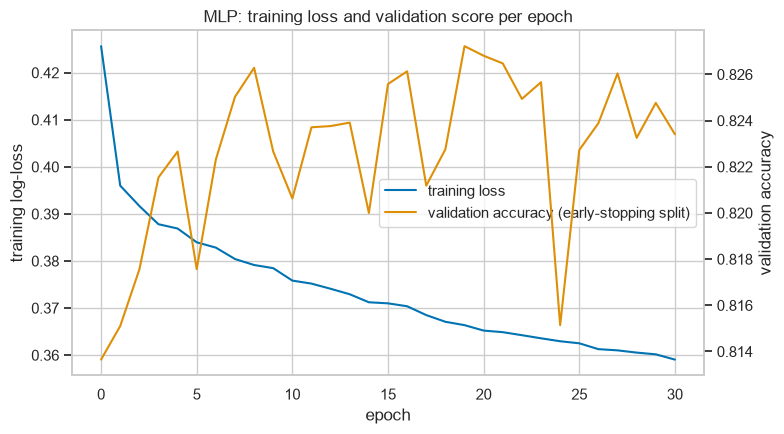

In [ ]:
fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax1.plot(mlp.loss_curve_, color='C0', label='training loss')
ax1.set_xlabel('epoch')
ax1.set_ylabel('training log-loss')
ax2 = ax1.twinx()
ax2.plot(mlp.validation_scores_, color='C1', label='validation accuracy (early-stopping split)')
ax2.set_ylabel('validation accuracy')
ax2.grid(False)
lines = ax1.get_lines() + ax2.get_lines()
ax1.legend(lines, [l.get_label() for l in lines], loc='center right')
ax1.set_title('MLP: training loss and validation score per epoch')
save_fig('m2_mlp_learning_curve.png')
plt.show()

**Observation.** The training loss falls smoothly every epoch, but the validation accuracy peaks around epoch 19
(~0.827) and then only fluctuates. Early stopping waits 10 epochs without improvement and stops at epoch 31 — past
that point more epochs would only fit the training rows more closely (overfitting).

## 4. Evaluation of the two tuned models

### 4.1 Tuning improvement

In [ ]:
rows = []
for name in models:
    for metric in ['accuracy', 'f1_weighted', 'f1_macro', 'roc_auc']:
        b, t = results[f'{name} (base)'][metric], results[f'{name} (tuned)'][metric]
        rows.append({'model': name, 'metric': metric, 'base': b, 'tuned': t, 'change': t - b,
                     'best_params': str(searches[name].best_params_)})
tuning_table = pd.DataFrame(rows)
display(tuning_table.round(4))
tuning_table.to_csv(RESULTS_DIR / 'partB_member2_tuning_results.csv', index=False)

,model,metric,base,tuned,change,best_params
0,Bagging,accuracy,0.8411,0.8459,0.0049,"{'estimator__max_depth': 20, 'max_samples': 0...."
1,Bagging,f1_weighted,0.8386,0.8493,0.0107,"{'estimator__max_depth': 20, 'max_samples': 0...."
2,Bagging,f1_macro,0.7804,0.8027,0.0223,"{'estimator__max_depth': 20, 'max_samples': 0...."
3,Bagging,roc_auc,0.8916,0.9135,0.0219,"{'estimator__max_depth': 20, 'max_samples': 0...."
4,MLP,accuracy,0.8104,0.8031,-0.0073,"{'activation': 'tanh', 'alpha': 0.01, 'hidden_..."
5,MLP,f1_weighted,0.8200,0.8143,-0.0058,"{'activation': 'tanh', 'alpha': 0.01, 'hidden_..."
6,MLP,f1_macro,0.7752,0.7712,-0.0040,"{'activation': 'tanh', 'alpha': 0.01, 'hidden_..."
7,MLP,roc_auc,0.9025,0.9075,0.0050,"{'activation': 'tanh', 'alpha': 0.01, 'hidden_..."


**Observation.** Tuning used CV on the training set only, so these test changes are honest estimates.
- **Bagging improves on every metric:** accuracy +0.005, weighted F1 +0.011, macro F1 +0.022, ROC-AUC +0.022.
- **MLP improves ROC-AUC (+0.005) and balanced accuracy**, but accuracy and weighted F1 dip slightly
  (-0.007 / -0.006), as explained in section 3.1.

### 4.2 Confusion matrices

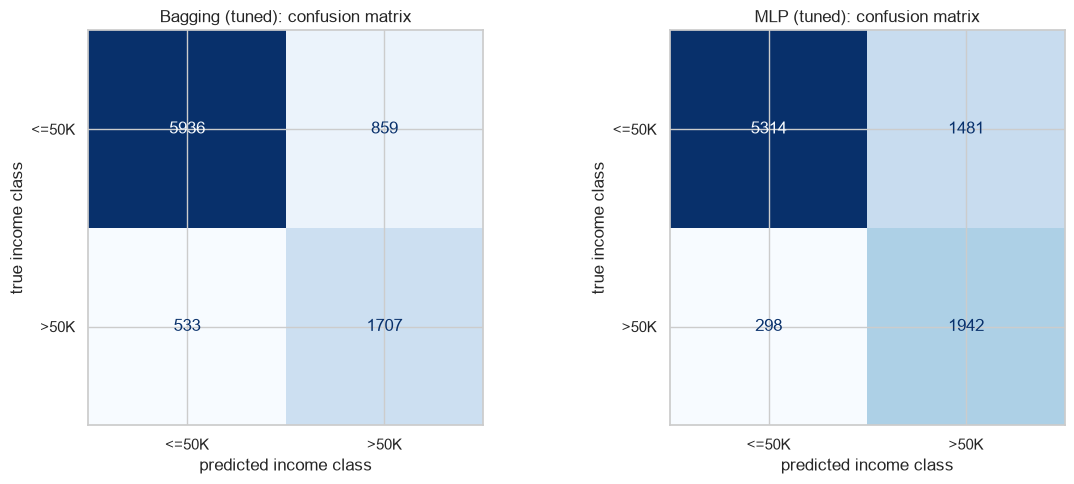

--- Bagging ---


              precision    recall  f1-score   support

       <=50K      0.918     0.874     0.895      6795
        >50K      0.665     0.762     0.710      2240

    accuracy                          0.846      9035
   macro avg      0.791     0.818     0.803      9035
weighted avg      0.855     0.846     0.849      9035

--- MLP ---
              precision    recall  f1-score   support

       <=50K      0.947     0.782     0.857      6795
        >50K      0.567     0.867     0.686      2240

    accuracy                          0.803      9035
   macro avg      0.757     0.825     0.771      9035
weighted avg      0.853     0.803     0.814      9035



In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, model) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test))
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(f'{name} (tuned): confusion matrix')
    ax.set_xlabel('predicted income class')
    ax.set_ylabel('true income class')
save_fig('partB_member2_confusion_matrices.png')
plt.show()

for name, model in models.items():
    print(f'--- {name} ---')
    print(classification_report(y_test, model.predict(X_test), target_names=class_names, digits=3))

**Observation.** The two models make opposite trade-offs on the minority class:
- **MLP** catches **87%** of `>50K` people (recall 0.867), but only 57% of its `>50K` predictions are right; it
  mislabels more `<=50K` people (recall 0.782).
- **Bagging** is more conservative: 76% recall and 67% precision on `>50K`, and 87% of `<=50K` people correct, which
  gives it the higher accuracy.

### 4.3 ROC curves

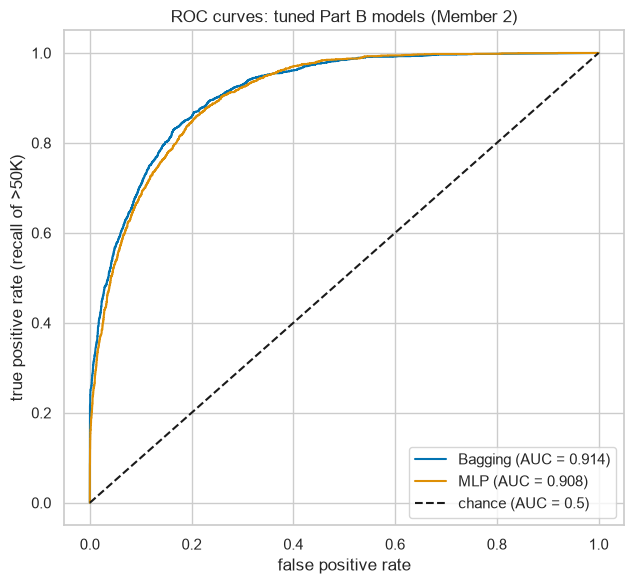

In [ ]:
plt.figure(figsize=(6.5, 6))
for name, model in models.items():
    fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {results[name + ' (tuned)']['roc_auc']:.3f})")
plt.plot([0, 1], [0, 1], 'k--', label='chance (AUC = 0.5)')
plt.title('ROC curves: tuned Part B models (Member 2)')
plt.xlabel('false positive rate')
plt.ylabel('true positive rate (recall of >50K)')
plt.legend(loc='lower right')
save_fig('partB_member2_roc_curves.png')
plt.show()

### 4.4 5-fold cross-validation of the tuned models

Stratified 5-fold CV on the training set checks that the test-set numbers are not a lucky split.

In [ ]:
cv_rows = []
for name, model in models.items():
    est = clone(model).set_params(n_jobs=1) if 'n_jobs' in model.get_params() else model
    fit_params = {'sample_weight': sw_train} if name == 'MLP' else None
    cv = cross_validate(est, X_train, y_train, cv=CV, n_jobs=-1, params=fit_params,
                        scoring=['accuracy', 'f1_weighted', 'roc_auc'])
    cv_rows.append({'model': name,
                    'cv_accuracy_mean': cv['test_accuracy'].mean(), 'cv_accuracy_std': cv['test_accuracy'].std(),
                    'cv_f1_weighted_mean': cv['test_f1_weighted'].mean(), 'cv_f1_weighted_std': cv['test_f1_weighted'].std(),
                    'cv_roc_auc_mean': cv['test_roc_auc'].mean(), 'cv_roc_auc_std': cv['test_roc_auc'].std()})
cv_results = pd.DataFrame(cv_rows).set_index('model')
display(cv_results.round(4))
cv_results.to_csv(RESULTS_DIR / 'partB_member2_cv_results.csv')

,cv_accuracy_mean,cv_accuracy_std,cv_f1_weighted_mean,cv_f1_weighted_std,cv_roc_auc_mean,cv_roc_auc_std
model,,,,,,
Bagging,0.8459,0.0039,0.8495,0.0039,0.9135,0.0030
MLP,0.8129,0.0075,0.8227,0.0064,0.9093,0.0036


**Observation.** CV means match the test scores (weighted F1: Bagging 0.850 CV vs 0.849 test, MLP 0.823 vs 0.814).
The MLP varies more between folds (std 0.006-0.008 vs 0.004 for Bagging): neural-network training depends on the
random weight initialisation and the early-stopping split, so it is less stable than an average of 150 trees.

## 5. Comparison with the other models and saved artefacts

Part A rows come from `results/classification/model_comparison.csv` (Review 1) and Member 1's Part B rows from
`partB_member1_model_comparison.csv`, all on the same test split.

In [ ]:
part_b = pd.DataFrame({name: results[name + ' (tuned)'] for name in models}).T
part_b.index.name = 'model'
part_b.to_csv(RESULTS_DIR / 'partB_member2_model_comparison.csv')

frames = [pd.read_csv(RESULTS_DIR / 'model_comparison.csv').set_index('model').assign(source='Part A')]
m1 = RESULTS_DIR / 'partB_member1_model_comparison.csv'
if m1.exists():
    frames.append(pd.read_csv(m1).set_index('model').assign(source='Part B (Member 1)'))
frames.append(part_b.assign(source='Part B (Member 2)'))
combined = pd.concat(frames)
cols = ['source', 'accuracy', 'precision_weighted', 'recall_weighted', 'f1_weighted', 'roc_auc', 'f1_macro', 'balanced_accuracy']
display(combined[cols].sort_values('f1_weighted', ascending=False).round(4))

for name, model in models.items():
    joblib.dump(model, MODELS_DIR / f"{name.lower().replace(' ', '_')}.pkl", compress=3)
print('saved:', [f"{name.lower().replace(' ', '_')}.pkl" for name in models])

,source,accuracy,precision_weighted,recall_weighted,f1_weighted,roc_auc,f1_macro,balanced_accuracy
model,,,,,,,,
Bagging,Part B (Member 2),0.8459,0.8550,0.8459,0.8493,0.9135,0.8027,0.8178
KNN,Part A,0.8393,0.8346,0.8393,0.8363,0.8972,0.7767,0.7675
Random Forest,Part B (Member 1),0.8330,0.8406,0.8330,0.8360,0.8968,0.7844,0.7959
AdaBoost,Part B (Member 1),0.8138,0.8506,0.8138,0.8231,0.9097,0.7786,0.8215
Decision Tree,Part A,0.8089,0.8490,0.8089,0.8188,0.8942,0.7741,0.8194
SVC,Part A,0.8071,0.8486,0.8071,0.8172,0.8952,0.7726,0.8188
MLP,Part B (Member 2),0.8031,0.8528,0.8031,0.8143,0.9075,0.7712,0.8245
Logistic Regression,Part A,0.7997,0.8422,0.7997,0.8103,0.8944,0.7640,0.8095
Majority-class baseline,Part A,0.7521,0.5656,0.7521,0.6457,0.5000,0.4292,0.5000


saved: ['bagging.pkl', 'mlp.pkl']


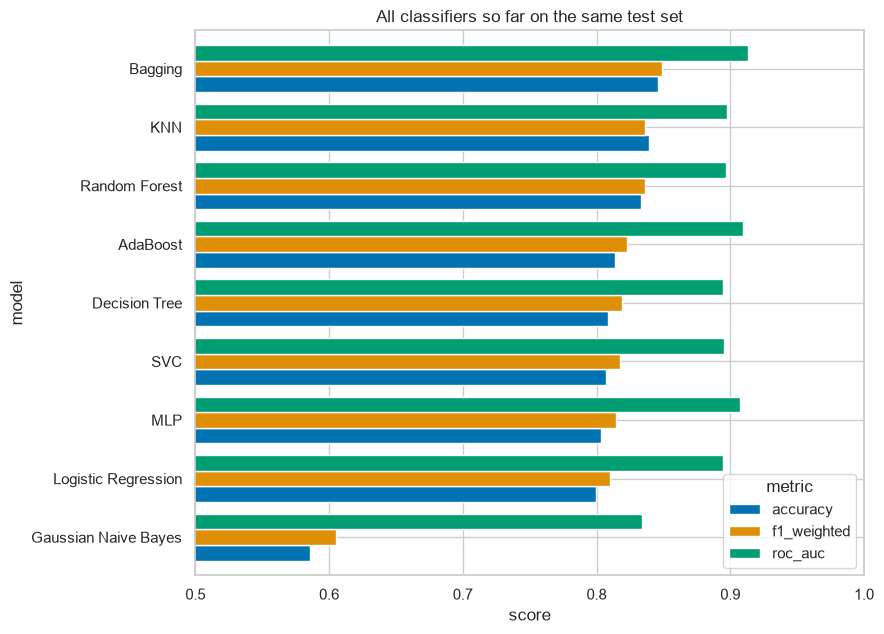

In [ ]:
plot_df = combined[combined.index != 'Majority-class baseline'][['accuracy', 'f1_weighted', 'roc_auc']].sort_values('f1_weighted')
ax = plot_df.plot.barh(figsize=(9, 6.5), width=0.8)
ax.set_title('All classifiers so far on the same test set')
ax.set_xlabel('score')
ax.set_ylabel('model')
ax.set_xlim(0.5, 1.0)
ax.legend(title='metric', loc='lower right')
save_fig('partB_member2_vs_others.png')
plt.show()

## 6. Summary

| Model | Best params | Accuracy | Weighted F1 | Macro F1 | ROC-AUC |
|---|---|---|---|---|---|
| Bagging (Decision Tree) | `max_samples=0.5, estimator__max_depth=20, n_estimators=150` | **0.846** | **0.849** | **0.803** | **0.914** |
| MLP Classifier | `hidden_layer_sizes=(64, 32), activation='tanh', alpha=0.01` | 0.803 | 0.814 | 0.771 | 0.908 |

- Preprocessing follows the Review 1 pipeline exactly: pooled UCI files, `?` rows and duplicates dropped (45,175
  rows), `log1p` on the capital columns, `net_capital` and `overtime` engineered, `fnlwgt` / `education` dropped,
  stratified 80:20 split, one-hot encoder and scaler fitted on the training set only.
- Both models were tuned with stratified 5-fold `GridSearchCV`. Bagging improved on every metric; the MLP improved
  ROC-AUC and balanced accuracy.
- **Bagging** has the best accuracy and weighted F1 of all classifiers so far. The **MLP** has the highest recall of
  high earners (0.867) but more false alarms.
- Saved: `models/classification/bagging.pkl`, `models/classification/mlp.pkl`,
  `results/classification/partB_member2_*.csv` (read by Member 3's consolidated A2/A3 notebook) and the
  `m2_*.png` / `partB_member2_*.png` plots.